In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## dataset-composition

**Figure 2: Composition of our instruction-tuning dataset by source.** Each wedge is a source's share of the 1.24M examples. Web forums (38%) and textbooks (24%) together make up 62% of the data.

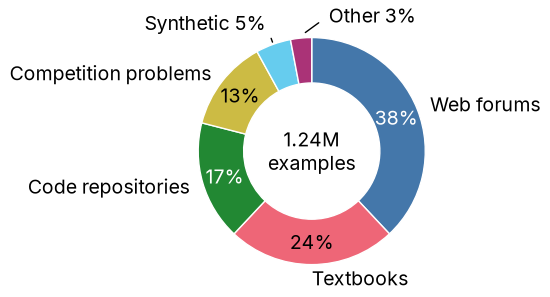

In [2]:
with open("../data/dataset-composition.json") as f:
    data = json.load(f)
names = list(data["sources"])
shares = list(data["sources"].values())
wedge_colors = [colors["series-1"], colors["series-2"], colors["series-3"],
                colors["series-4"], colors["series-5"], colors["series-6"]]

fig, ax = plt.subplots(figsize=(2.75, 2.75))
wedges, _ = ax.pie(shares, colors=wedge_colors, startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.4, edgecolor="white", linewidth=0.5))

for w, name, share, color in zip(wedges, names, shares, wedge_colors):
    mid = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(mid), np.sin(mid)
    ha = "left" if x > 0 else "right"
    if share >= 0.06:
        ax.text(0.8 * x, 0.8 * y, f"{share:.0%}", ha="center", va="center", color=text_color(color))
        ax.annotate(name, (1.02 * x, 1.02 * y), xytext=(1.12 * x, 1.12 * y), ha=ha, va="center")
    else:
        text_x = 1.2 * x if name != "Other" else 0.15
        ha = "left" if text_x > 0 else "right"
        ax.annotate(f"{name} {share:.0%}", (1.02 * x, 1.02 * y), xytext=(text_x, 1.2 * y), ha=ha, va="center",
                    arrowprops=dict(arrowstyle="-", color=colors["ink"], linewidth=0.5,
                                    relpos=(0, 0.5) if ha == "left" else (1, 0.5)))

ax.text(0, 0, f"{data['total_examples'] / 1e6:.2f}M\nexamples", ha="center", va="center")

fit_height(fig, ax)
fig.savefig("../outputs/dataset-composition.pdf")
fig.savefig("../outputs/dataset-composition.png")
plt.show()